# Sales Data Analysis & Business Intelligence Project
### Summer Internship Project — Queenbug Technologies, Tirupattur
**Author:** Data Analytics Intern  
**Domain:** Retail Sales & Commercial Analytics  
**Tools & Stack:** Python (3.10+), Pandas, NumPy, Matplotlib, OpenPyXL, MySQL, Jupyter Notebook, Git/GitHub  

---

## Project Overview
This notebook documents the step-by-step data analytics workflow for a retail enterprise operating across Indian regional markets during 2025. The raw transactional data exhibits typical real-world imperfections (duplicates, clerical sign errors in quantities, mixed datetime string formats, missing values, and inconsistent text casing). 

### End-to-End Workflow:
1. **Data Ingestion (Collect):** Load the raw 2,500+ order dataset.
2. **Data Cleaning:** Handle duplicate rows, negative quantities, inconsistent text casing/whitespace, parse mixed date formats, and impute missing attributes.
3. **Preprocessing & Feature Engineering:** Derive Month, Quarter, Weekday, Gross Revenue, Discount Amount, and verify Net Revenue.
4. **Exploratory Sales Analysis:** Analyze performance by Product, Category, Region, City, Month, Quarter, Payment Channel, and Weekday.
5. **Visualizations:** Render 8 high-resolution Matplotlib charts.
6. **Reporting:** Export a multi-sheet Excel workbook with a Data Quality Log and generate a verifiable business insights summary.

## 1. Environment Setup & Library Imports

In [3]:
import os
import sys
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Set display options for clear tabular output
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Ensure output directories exist
os.makedirs('data', exist_ok=True)
os.makedirs('charts', exist_ok=True)
os.makedirs('output', exist_ok=True)

print('All libraries imported successfully!')

All libraries imported successfully!


## 2. Data Collection (Ingestion)

In [5]:
# Load raw sales records
raw_data_path = 'data/raw_sales_data.csv'
df_raw = pd.read_csv(raw_data_path)

print(f"Raw Dataset Loaded: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns\n")
display(df_raw.head())

Raw Dataset Loaded: 2545 rows x 12 columns

         Order_ID   Order_Date Customer_ID            Product         Category Region       City  Quantity  Unit_Price  Discount_Pct Payment_Mode   Revenue
0  ORD-2025-00001   2025-11-24   CUST-0113    Ergonomic Chair        Furniture   East      patna         3        7500          5.00          UPI 21,375.00
1  ORD-2025-00002   05-21-2025   CUST-0215         Smartphone      Electronics  South  Bengaluru         4       22000         10.00   Debit Card 79,200.00
2  ORD-2025-00003   2025-02-22   CUST-0480          USB-C Hub      Electronics   East      Patna         3        1200          0.00          UPI  3,600.00
3  ORD-2025-00004   14/02/2025   CUST-0317  bluetooth speaker      electronics  South    Chennai         2        1800          5.00          UPI  3,420.00
4  ORD-2025-00005  16-Jan-2025   CUST-0212      Paper Ream A4  Office Supplies  South  Bengaluru         1         350          5.00  Credit Card    332.50


## 3. Initial Data Quality Audit
We inspect missing values, data types, duplicate counts, and identify potential anomalies before applying transformations.

In [7]:
print("=== DATA INFORMATION & DTYPES ===")
df_raw.info()

print("\n=== MISSING VALUE COUNTS ===")
print(df_raw.isna().sum())

print("\n=== EXACT DUPLICATE ROWS ===")
print(f"Duplicates found: {df_raw.duplicated().sum()}")

print("\n=== ANOMALOUS QUANTITIES (< 0) ===")
print(f"Negative quantities found: {(df_raw['Quantity'] < 0).sum()}")

=== DATA INFORMATION & DTYPES ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2545 entries, 0 to 2544
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order_ID      2545 non-null   object 
 1   Order_Date    2545 non-null   object 
 2   Customer_ID   2517 non-null   object 
 3   Product       2545 non-null   object 
 4   Category      2545 non-null   object 
 5   Region        2545 non-null   object 
 6   City          2513 non-null   object 
 7   Quantity      2545 non-null   int64  
 8   Unit_Price    2545 non-null   int64  
 9   Discount_Pct  2519 non-null   float64
 10  Payment_Mode  2503 non-null   object 
 11  Revenue       2545 non-null   float64
dtypes: float64(2), int64(2), object(8)
memory usage: 238.7+ KB

=== MISSING VALUE COUNTS ===
Order_ID         0
Order_Date       0
Customer_ID     28
Product          0
Category         0
Region           0
City            32
Quantity         0
Unit_Price 

## 4. Data Cleaning Pipeline
We execute systematic data sanitation:
1. **Deduplication:** Remove identical records.
2. **Negative Quantity Rectification:** Convert negative values to positive absolute values (resolving clerical entry sign flips).
3. **Text Normalization:** Trim whitespace and enforce proper Title-Case.
4. **Mixed Date Parsing:** Standardize diverse date strings (`YYYY-MM-DD`, `DD/MM/YYYY`, `MM-DD-YYYY`, `DD-Mon-YYYY`) into ISO datetime.
5. **Imputation:** Populate missing customer IDs (`CUST-GUEST`), payment modes (dominant mode `UPI`), cities (regional hubs), and discounts (`0.0%`).

In [9]:
df_clean = df_raw.copy()
quality_audit = {}
quality_audit['initial_records'] = len(df_raw)

# 1. Deduplication
dups = df_clean.duplicated().sum()
quality_audit['duplicates_removed'] = int(dups)
df_clean.drop_duplicates(inplace=True)
df_clean.reset_index(drop=True, inplace=True)

# 2. Negative Quantities
neg_q = (df_clean['Quantity'] < 0).sum()
quality_audit['negative_quantities_fixed'] = int(neg_q)
df_clean['Quantity'] = df_clean['Quantity'].abs().astype(int)

# 3. Standardize Text
text_cols = ['Category', 'Product', 'City', 'Region']
for col in text_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype(str).str.strip().str.title()
        df_clean[col] = df_clean[col].replace('Nan', np.nan)

df_clean['Product'] = df_clean['Product'].str.replace('Usb-C Hub', 'USB-C Hub')
df_clean['Product'] = df_clean['Product'].str.replace('Paper Ream A4', 'Paper Ream (A4)')

# Standardize Payment Mode
def standardize_payment(p):
    if pd.isna(p) or str(p).strip().lower() == 'nan':
        return np.nan
    s = str(p).strip().upper()
    if 'UPI' in s:
        return 'UPI'
    elif 'CREDIT' in s:
        return 'Credit Card'
    elif 'DEBIT' in s:
        return 'Debit Card'
    elif 'NET' in s or 'BANK' in s:
        return 'Net Banking'
    elif 'CASH' in s or 'COD' in s:
        return 'Cash on Delivery'
    return str(p).strip().title()

df_clean['Payment_Mode'] = df_clean['Payment_Mode'].apply(standardize_payment)

# 4. Parse Mixed Dates (robust parser handling ISO, British, US and abbreviated month formats)
def parse_mixed_date(val):
    if pd.isna(val):
        return pd.NaT
    s = str(val).strip()
    for fmt in ['%Y-%m-%d', '%d/%m/%Y', '%m-%d-%Y', '%d-%b-%Y', '%Y/%m/%d']:
        try:
            return pd.to_datetime(s, format=fmt)
        except Exception:
            continue
    return pd.to_datetime(s, errors='coerce')

df_clean['Order_Date'] = df_clean['Order_Date'].apply(parse_mixed_date)
quality_audit['date_errors'] = int(df_clean['Order_Date'].isna().sum())

# 5. Impute Missing Values
quality_audit['imputed_customers'] = int(df_clean['Customer_ID'].isna().sum())
df_clean['Customer_ID'] = df_clean['Customer_ID'].fillna('CUST-GUEST')

quality_audit['imputed_payment_modes'] = int(df_clean['Payment_Mode'].isna().sum())
mode_pmt = df_clean['Payment_Mode'].mode()[0] if not df_clean['Payment_Mode'].mode().empty else 'UPI'
df_clean['Payment_Mode'] = df_clean['Payment_Mode'].fillna(mode_pmt)

quality_audit['imputed_discounts'] = int(df_clean['Discount_Pct'].isna().sum())
df_clean['Discount_Pct'] = df_clean['Discount_Pct'].fillna(0.0)

quality_audit['imputed_cities'] = int(df_clean['City'].isna().sum())
region_hubs = {'South': 'Chennai', 'North': 'Delhi', 'West': 'Mumbai', 'East': 'Kolkata'}
df_clean['City'] = df_clean.apply(
    lambda r: region_hubs.get(r['Region'], 'Metro Hub') if pd.isna(r['City']) else r['City'],
    axis=1
)

quality_audit['final_clean_rows'] = len(df_clean)

print("Cleaning completed successfully!")
print(pd.Series(quality_audit))

Cleaning completed successfully!
initial_records              2545
duplicates_removed             45
negative_quantities_fixed      35
date_errors                     0
imputed_customers              28
imputed_payment_modes          42
imputed_discounts              26
imputed_cities                 32
final_clean_rows             2500
dtype: int64


## 5. Preprocessing & Revenue Recalculation

In [11]:
# Derive temporal features
df_clean['Month_Num'] = df_clean['Order_Date'].dt.month
df_clean['Month'] = df_clean['Order_Date'].dt.strftime('%b')
df_clean['Quarter'] = 'Q' + df_clean['Order_Date'].dt.quarter.astype(str)
df_clean['Weekday'] = df_clean['Order_Date'].dt.day_name()

# Ensure numeric types
df_clean['Quantity'] = df_clean['Quantity'].astype(int)
df_clean['Unit_Price'] = df_clean['Unit_Price'].astype(float)
df_clean['Discount_Pct'] = df_clean['Discount_Pct'].astype(float)

# Recompute mathematically sound revenues
df_clean['Gross_Revenue'] = (df_clean['Quantity'] * df_clean['Unit_Price']).round(2)
df_clean['Discount_Amount'] = (df_clean['Gross_Revenue'] * (df_clean['Discount_Pct'] / 100.0)).round(2)
df_clean['Revenue'] = (df_clean['Gross_Revenue'] - df_clean['Discount_Amount']).round(2)

# Bin into discount tiers
def tier_discount(pct):
    if pct == 0:
        return 'No Discount (0%)'
    elif pct <= 10:
        return 'Low (1% - 10%)'
    elif pct <= 20:
        return 'Moderate (11% - 20%)'
    else:
        return 'High (> 20%)'

df_clean['Discount_Tier'] = df_clean['Discount_Pct'].apply(tier_discount)

display(df_clean[['Order_ID', 'Order_Date', 'Product', 'Quantity', 'Unit_Price', 'Discount_Pct', 'Revenue', 'Quarter', 'Weekday']].head())

         Order_ID Order_Date            Product  Quantity  Unit_Price  Discount_Pct   Revenue Quarter    Weekday
0  ORD-2025-00001 2025-11-24    Ergonomic Chair         3    7,500.00          5.00 21,375.00      Q4     Monday
1  ORD-2025-00002 2025-05-21         Smartphone         4   22,000.00         10.00 79,200.00      Q2  Wednesday
2  ORD-2025-00003 2025-02-22          USB-C Hub         3    1,200.00          0.00  3,600.00      Q1   Saturday
3  ORD-2025-00004 2025-02-14  Bluetooth Speaker         2    1,800.00          5.00  3,420.00      Q1     Friday
4  ORD-2025-00005 2025-01-16    Paper Ream (A4)         1      350.00          5.00    332.50      Q1   Thursday


## 6. Exploratory Data Analysis & Business KPIs

In [13]:
# Overall KPIs
total_rev = df_clean['Revenue'].sum()
total_orders = len(df_clean)
aov = df_clean['Revenue'].mean()
total_units = df_clean['Quantity'].sum()
avg_disc = df_clean['Discount_Pct'].mean()

print("=== EXECUTIVE KPIS (2025) ===")
print(f"Total Net Revenue: INR {total_rev:,.2f}")
print(f"Total Orders:      {total_orders:,}")
print(f"Total Units Sold:  {total_units:,}")
print(f"Average Order Val: INR {aov:,.2f}")
print(f"Average Discount:  {avg_disc:.2f}%")

=== EXECUTIVE KPIS (2025) ===
Total Net Revenue: INR 35,784,911.50
Total Orders:      2,500
Total Units Sold:  5,474
Average Order Val: INR 14,313.96
Average Discount:  6.81%


### 6.1 Category and Product Performance

In [15]:
cat_summary = df_clean.groupby('Category').agg(
    Total_Revenue=('Revenue', 'sum'),
    Orders=('Order_ID', 'count'),
    Units_Sold=('Quantity', 'sum'),
    Avg_Order_Value=('Revenue', 'mean')
).reset_index()
cat_summary['Revenue_Share_%'] = (cat_summary['Total_Revenue'] / total_rev * 100).round(2)
cat_summary = cat_summary.sort_values(by='Total_Revenue', ascending=False)
display(cat_summary)

          Category  Total_Revenue  Orders  Units_Sold  Avg_Order_Value  Revenue_Share_%
1      Electronics  25,860,500.00     778        1779        33,239.72            72.27
2        Furniture   4,752,325.00     387         858        12,279.91            13.28
3   Home & Kitchen   3,276,250.00     361         769         9,075.48             9.16
0         Clothing   1,574,635.00     486        1019         3,239.99             4.40
4  Office Supplies     321,201.50     488        1049           658.20             0.90


In [16]:
prod_summary = df_clean.groupby(['Product', 'Category']).agg(
    Total_Revenue=('Revenue', 'sum'),
    Orders=('Order_ID', 'count'),
    Units_Sold=('Quantity', 'sum'),
    Unit_Price=('Unit_Price', 'mean')
).reset_index().sort_values(by='Total_Revenue', ascending=False)

print("Top 10 Products by Revenue:")
display(prod_summary.head(10))

Top 10 Products by Revenue:
                Product        Category  Total_Revenue  Orders  Units_Sold  Unit_Price
12               Laptop     Electronics  17,327,750.00     130         337   55,000.00
16           Smartphone     Electronics   6,029,100.00     132         294   22,000.00
20           Study Desk       Furniture   2,079,775.00      78         192   11,500.00
22       Water Purifier  Home & Kitchen   1,470,725.00      81         178    8,900.00
8       Ergonomic Chair       Furniture   1,065,000.00      81         152    7,500.00
17           Smartwatch     Electronics   1,016,050.00     137         312    3,500.00
0             Air Fryer  Home & Kitchen     726,600.00      66         139    5,600.00
9        Filing Cabinet       Furniture     695,240.00      63         143    5,200.00
25  Wireless Headphones     Electronics     649,880.00     112         252    2,800.00
2             Bookshelf       Furniture     642,810.00      72         164    4,200.00


### 6.2 Regional and Municipal Performance

In [18]:
reg_summary = df_clean.groupby('Region').agg(
    Total_Revenue=('Revenue', 'sum'),
    Orders=('Order_ID', 'count'),
    Units_Sold=('Quantity', 'sum'),
    Avg_Order_Value=('Revenue', 'mean')
).reset_index()
reg_summary['Revenue_Share_%'] = (reg_summary['Total_Revenue'] / total_rev * 100).round(2)
display(reg_summary.sort_values(by='Total_Revenue', ascending=False))

  Region  Total_Revenue  Orders  Units_Sold  Avg_Order_Value  Revenue_Share_%
2  South  17,149,867.00    1071        2380        16,012.95            47.92
1  North   9,104,237.00     652        1427        13,963.55            25.44
3   West   5,947,642.00     481        1041        12,365.16            16.62
0   East   3,583,165.50     296         626        12,105.29            10.01


### 6.3 Temporal Trends (Monthly & Quarterly)

In [20]:
monthly_summary = df_clean.groupby(['Month_Num', 'Month']).agg(
    Total_Revenue=('Revenue', 'sum'),
    Orders=('Order_ID', 'count'),
    Units_Sold=('Quantity', 'sum'),
    Avg_Order_Value=('Revenue', 'mean')
).reset_index().sort_values(by='Month_Num')
monthly_summary['MoM_Growth_%'] = (monthly_summary['Total_Revenue'].pct_change() * 100).round(2)
display(monthly_summary)

    Month_Num Month  Total_Revenue  Orders  Units_Sold  Avg_Order_Value  MoM_Growth_%
0           1   Jan   2,623,766.00     190         427        13,809.29           NaN
1           2   Feb   3,254,184.00     187         446        17,402.05         24.03
2           3   Mar   2,751,698.00     218         456        12,622.47        -15.44
3           4   Apr   2,810,912.00     195         417        14,414.93          2.15
4           5   May   3,588,436.00     219         474        16,385.55         27.66
5           6   Jun   2,543,007.00     211         423        12,052.17        -29.13
6           7   Jul   2,899,223.50     207         473        14,005.91         14.01
7           8   Aug   2,938,782.00     219         479        13,419.10          1.36
8           9   Sep   2,637,362.50     204         450        12,928.25        -10.26
9          10   Oct   4,204,908.50     217         482        19,377.46         59.44
10         11   Nov   3,363,122.00     191         441

## 7. Visualizations (8 Matplotlib Figures)

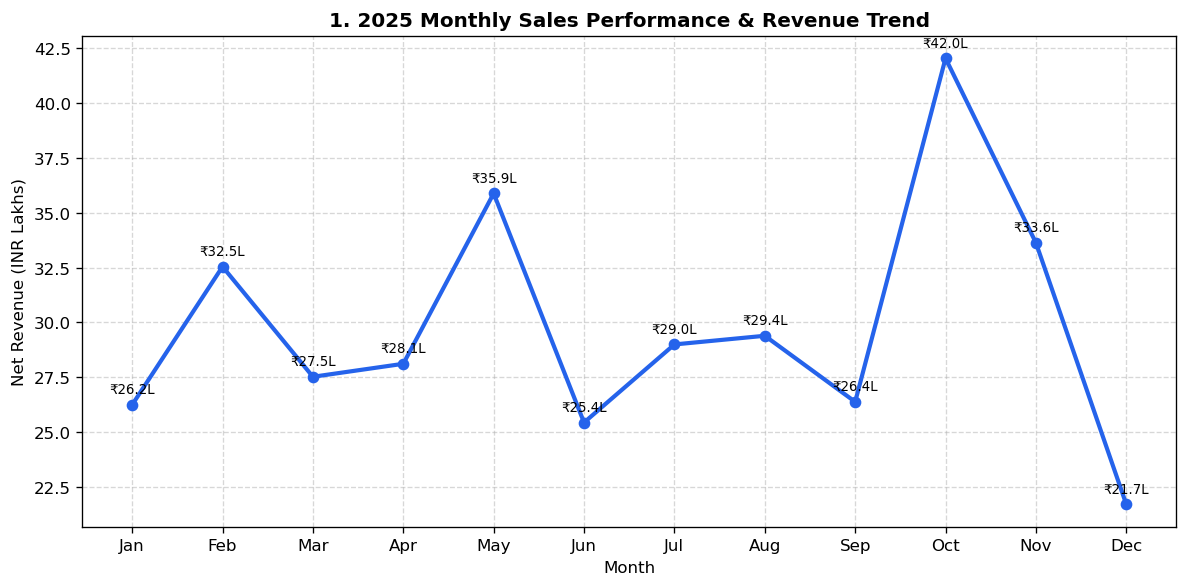

In [22]:
# Chart 1: Monthly Sales Trend
plt.figure(figsize=(10, 5), dpi=120)
plt.plot(monthly_summary['Month'], monthly_summary['Total_Revenue'] / 100000, marker='o', color='#2563EB', linewidth=2.5)
plt.title('1. 2025 Monthly Sales Performance & Revenue Trend', fontsize=12, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Net Revenue (INR Lakhs)')
plt.grid(True, linestyle='--', alpha=0.5)
for i, v in enumerate(monthly_summary['Total_Revenue'] / 100000):
    plt.annotate(f'₹{v:.1f}L', (monthly_summary['Month'].iloc[i], v), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('charts/1_monthly_sales_trend.png')
plt.show()

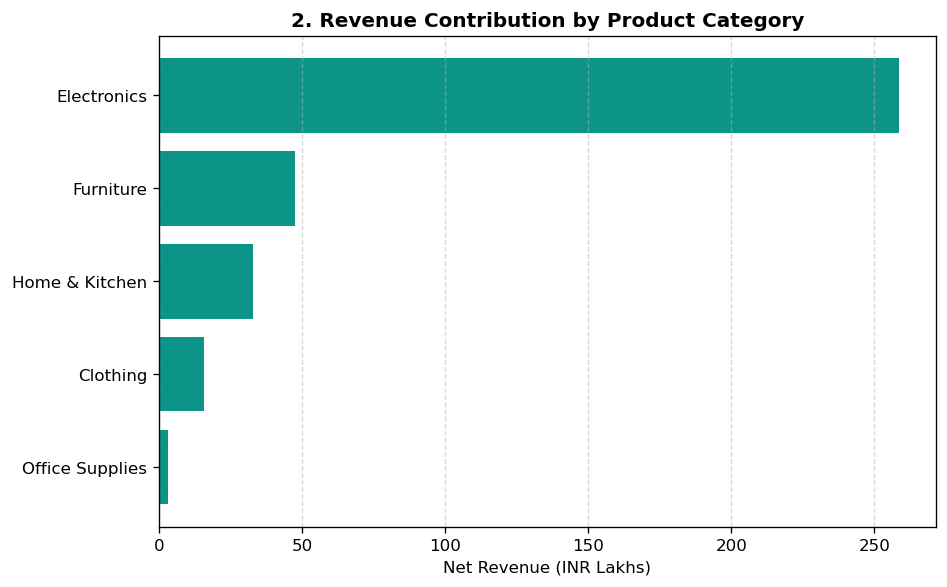

In [23]:
# Chart 2: Revenue by Category
plt.figure(figsize=(8, 5), dpi=120)
plt.barh(cat_summary['Category'][::-1], cat_summary['Total_Revenue'][::-1] / 100000, color='#0D9488')
plt.title('2. Revenue Contribution by Product Category', fontsize=12, fontweight='bold')
plt.xlabel('Net Revenue (INR Lakhs)')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('charts/2_revenue_by_category.png')
plt.show()

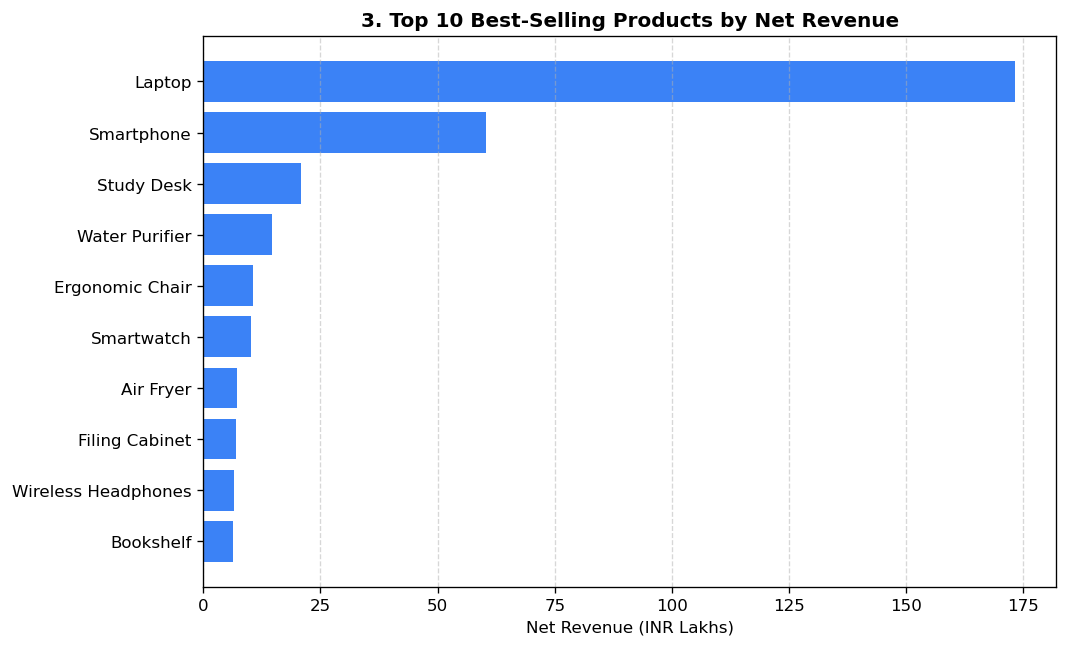

In [24]:
# Chart 3: Top 10 Products by Revenue
top10 = prod_summary.head(10).sort_values(by='Total_Revenue', ascending=True)
plt.figure(figsize=(9, 5.5), dpi=120)
plt.barh(top10['Product'], top10['Total_Revenue'] / 100000, color='#3B82F6')
plt.title('3. Top 10 Best-Selling Products by Net Revenue', fontsize=12, fontweight='bold')
plt.xlabel('Net Revenue (INR Lakhs)')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('charts/3_top_products_revenue.png')
plt.show()

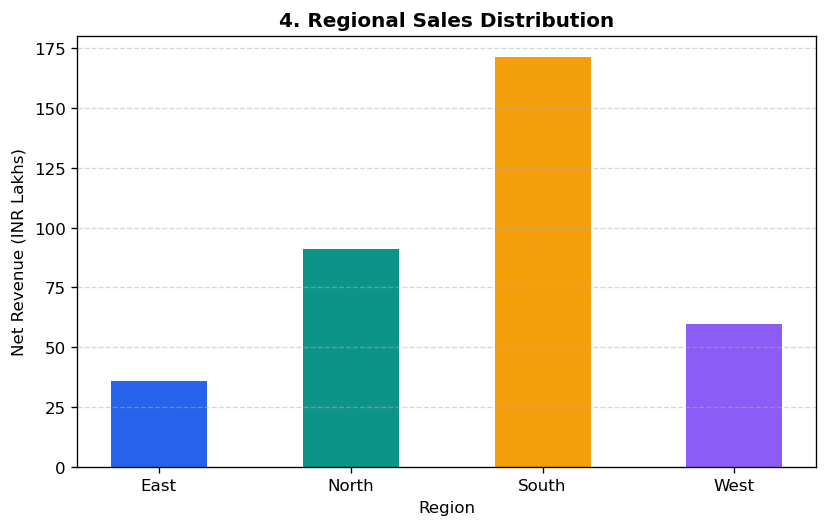

In [25]:
# Chart 4: Regional Distribution
plt.figure(figsize=(7, 4.5), dpi=120)
plt.bar(reg_summary['Region'], reg_summary['Total_Revenue'] / 100000, color=['#2563EB', '#0D9488', '#F59E0B', '#8B5CF6'], width=0.5)
plt.title('4. Regional Sales Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Net Revenue (INR Lakhs)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('charts/4_regional_sales_distribution.png')
plt.show()

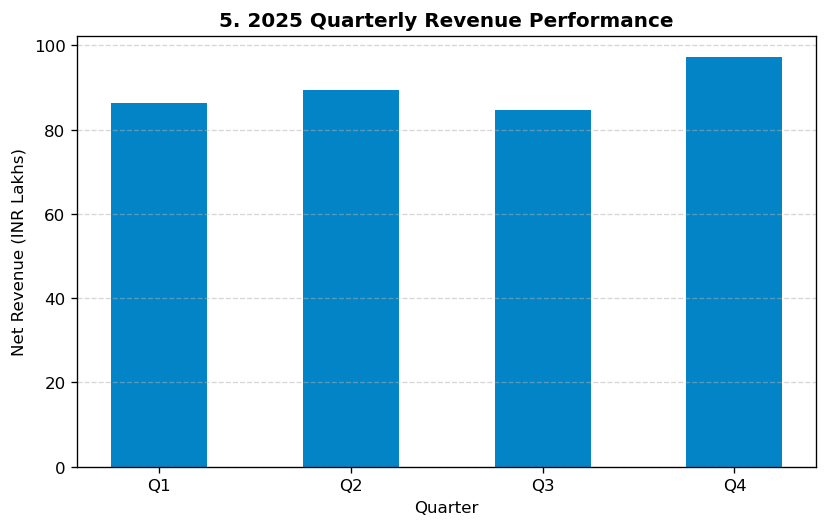

In [26]:
# Chart 5: Quarterly Performance
q_summary = df_clean.groupby('Quarter').agg(Revenue=('Revenue', 'sum'), Orders=('Order_ID', 'count')).reset_index()
plt.figure(figsize=(7, 4.5), dpi=120)
plt.bar(q_summary['Quarter'], q_summary['Revenue'] / 100000, color='#0284C7', width=0.5)
plt.title('5. 2025 Quarterly Revenue Performance', fontsize=12, fontweight='bold')
plt.xlabel('Quarter')
plt.ylabel('Net Revenue (INR Lakhs)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('charts/5_quarterly_performance.png')
plt.show()

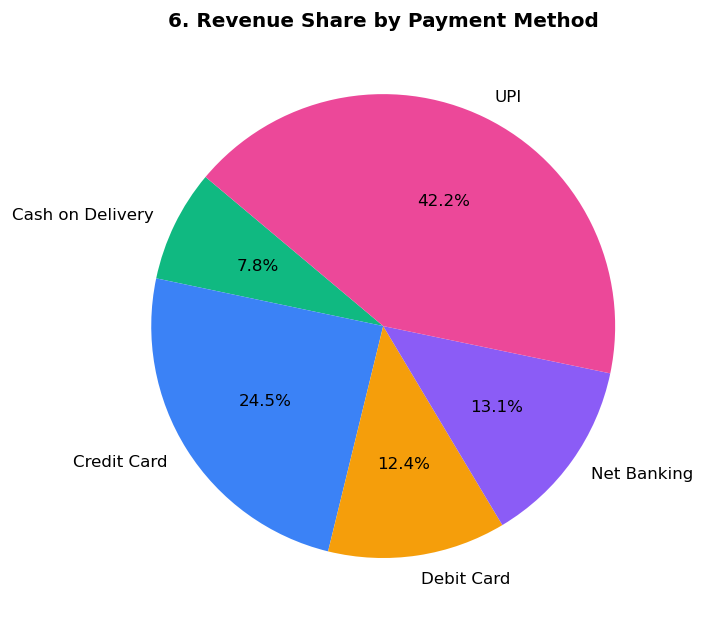

In [27]:
# Chart 6: Payment Mode Share
pmt_summary = df_clean.groupby('Payment_Mode')['Revenue'].sum().reset_index()
plt.figure(figsize=(6, 6), dpi=120)
plt.pie(pmt_summary['Revenue'], labels=pmt_summary['Payment_Mode'], autopct='%1.1f%%', startangle=140, colors=['#10B981', '#3B82F6', '#F59E0B', '#8B5CF6', '#EC4899'])
plt.title('6. Revenue Share by Payment Method', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('charts/6_payment_mode_share.png')
plt.show()

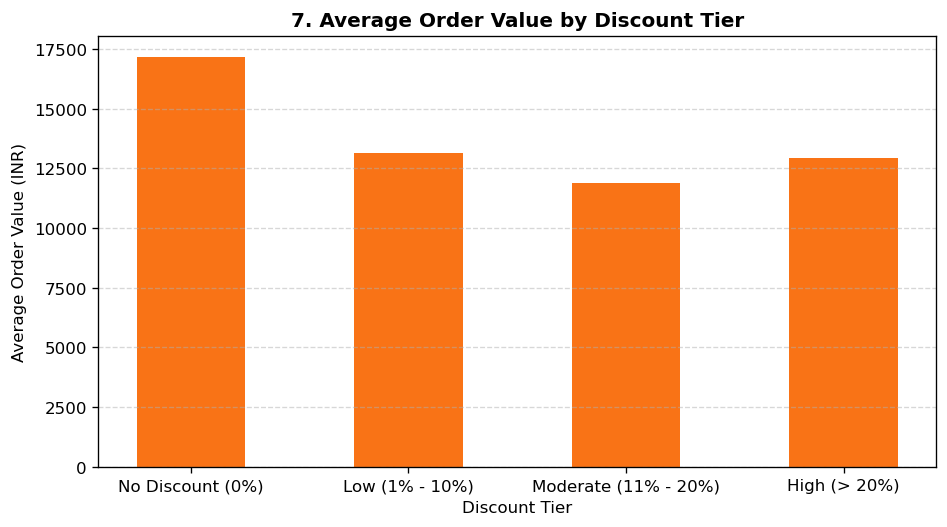

In [28]:
# Chart 7: Discount Tiers vs AOV
disc_summary = df_clean.groupby('Discount_Tier').agg(AOV=('Revenue', 'mean'), Units=('Quantity', 'mean')).reindex(
    ['No Discount (0%)', 'Low (1% - 10%)', 'Moderate (11% - 20%)', 'High (> 20%)']
).dropna().reset_index()
plt.figure(figsize=(8, 4.5), dpi=120)
plt.bar(disc_summary['Discount_Tier'], disc_summary['AOV'], color='#F97316', width=0.5)
plt.title('7. Average Order Value by Discount Tier', fontsize=12, fontweight='bold')
plt.xlabel('Discount Tier')
plt.ylabel('Average Order Value (INR)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('charts/7_discount_vs_revenue.png')
plt.show()

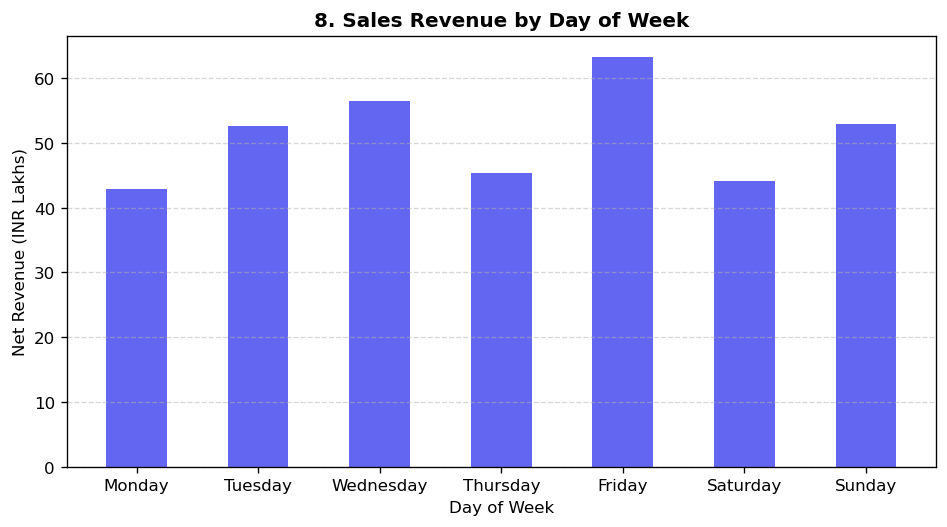

In [29]:
# Chart 8: Day of Week Performance
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_summary = df_clean.groupby('Weekday')['Revenue'].sum().reindex(day_order).reset_index()
plt.figure(figsize=(8, 4.5), dpi=120)
plt.bar(dow_summary['Weekday'], dow_summary['Revenue'] / 100000, color='#6366F1', width=0.5)
plt.title('8. Sales Revenue by Day of Week', fontsize=12, fontweight='bold')
plt.xlabel('Day of Week')
plt.ylabel('Net Revenue (INR Lakhs)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('charts/8_day_of_week_sales.png')
plt.show()

## 8. Exporting Excel Workbook & Key Insights

In [31]:
# Generate multi-tab Excel workbook
excel_path = 'output/sales_analysis_report.xlsx'
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    cat_summary.to_excel(writer, sheet_name='Category_Sales', index=False)
    prod_summary.head(25).to_excel(writer, sheet_name='Top_Products', index=False)
    reg_summary.to_excel(writer, sheet_name='Regional_Sales', index=False)
    monthly_summary.to_excel(writer, sheet_name='Monthly_Trends', index=False)
    pmt_summary.to_excel(writer, sheet_name='Payment_Modes', index=False)
    pd.DataFrame(list(quality_audit.items()), columns=['Metric', 'Value']).to_excel(writer, sheet_name='Data_Quality_Log', index=False)

print(f"Excel report successfully written to {excel_path}")

Excel report successfully written to output/sales_analysis_report.xlsx
